<a href="https://colab.research.google.com/github/juyeontech00-hue/TIL/blob/main/1_04_cv2_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

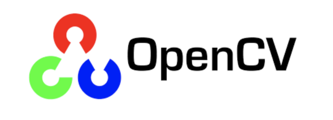

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Google Colab에서 drive라는 기능을 불러오고, 내 Google Drive를 Colab의 /content/drive 위치에 연결해 줘.
# mount() 컴퓨터에서 저장장치를 특정 폴더에 연결하여 접근할 수 있도록 하는 작업

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import cv2
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow  # Import cv2_imshow

# 오픈CV란 이미지와 동영상을 처리하고 분석하는데 사용하는 오픈소스 라이브러리

In [ ]:
# !pip list

In [ ]:
## 버전확인
print(cv2.__version__)

4.14.0


In [ ]:
# 1. 이미지 읽기
image = cv2.imread('/content/dog1.PNG')  # 이미지 파일 경로 입력

# image = cv2.imread('dog1.PNG') 라고 해도 실행은 됨! (상대경로)

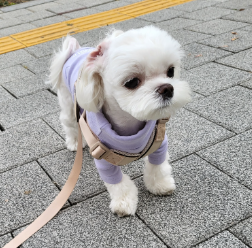

In [ ]:
# 이미지 표시
cv2_imshow(image)

In [ ]:
# 이미지 표시
# cv2.imshow('Image Window', image)

# 키보드 입력 대기 (0 무한정 대기)
# cv2.waitKey(0)

# cv2.waitKey(3000) = 최대 약 3초 동안 키보드 입력을 기다린다

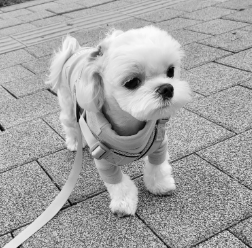

-1

In [ ]:
# 2. 그레이스케일 변환
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
cv2_imshow(gray_image)
cv2.waitKey(0)

# cv2.imread() → 이미지를 파일에서 읽기
# cv2.cvtColor() → 이미지의 색상 표현 방식 변환하기
# cv2_imshow() → 이미지를 화면에 보여주기

In [ ]:
cv2.imwrite('gray.png', gray_image)

# imwrite()	이미지 파일을 저장하는 함수

True

In [ ]:
save_path = "/content/gray.png"   # 또는 gray.jpg
cv2.imwrite(save_path, gray_image)

True

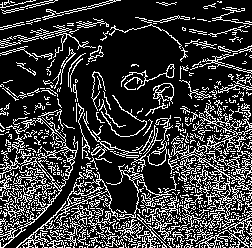

-1

In [ ]:
# 3. 가장자리 검출 (Canny Edge Detection)
edges = cv2.Canny(gray_image, 100, 200)
cv2_imshow(edges)
cv2.waitKey(0)

# 컴퓨터 비전 수업에서 가장자리나 픽셀값을 정확히 보존하려면 PNG가 유리할 수 있다
# Canny Edge Detection은 이미지에서 가장자리(Edge)를 검출하는 알고리즘이다 이미지의 가장자리란 물체의 윤곽선처럼 픽셀의 밝기가 급격하게 변하는 부분
# .Canny()	Canny 가장자리 검출 함수
# 100과 200은 이미지의 가장자리를 얼마나 민감하게 검출할지 결정하는 기준값으로 낮은 임계값, 높은 임계값 의미

In [ ]:
# 4. 이미지 저장
cv2.imwrite('edges_output.jpg', edges)

True

In [ ]:

# 5. 이미지 종료
cv2.destroyAllWindows()


**비디오 처리**

In [ ]:
# 영상의 모든 프레임을 그레이스케일로 변환 -> 출력

In [ ]:
import time
from IPython.display import clear_output

# clear_output	이전 출력 내용을 지우는 함수 (동영상은 너무 용량이 크니까)

In [ ]:
### 비디오 파일 불러오기
cap = cv2.VideoCapture('/content/video1.mp4')

In [ ]:
show_every = 10      # N프레임마다 1번 출력 (속도 조절)
max_frames = 300     # 최대 처리 프레임 수 제한
timeout_sec = 10     # 최대 실행 시간(초) 제한

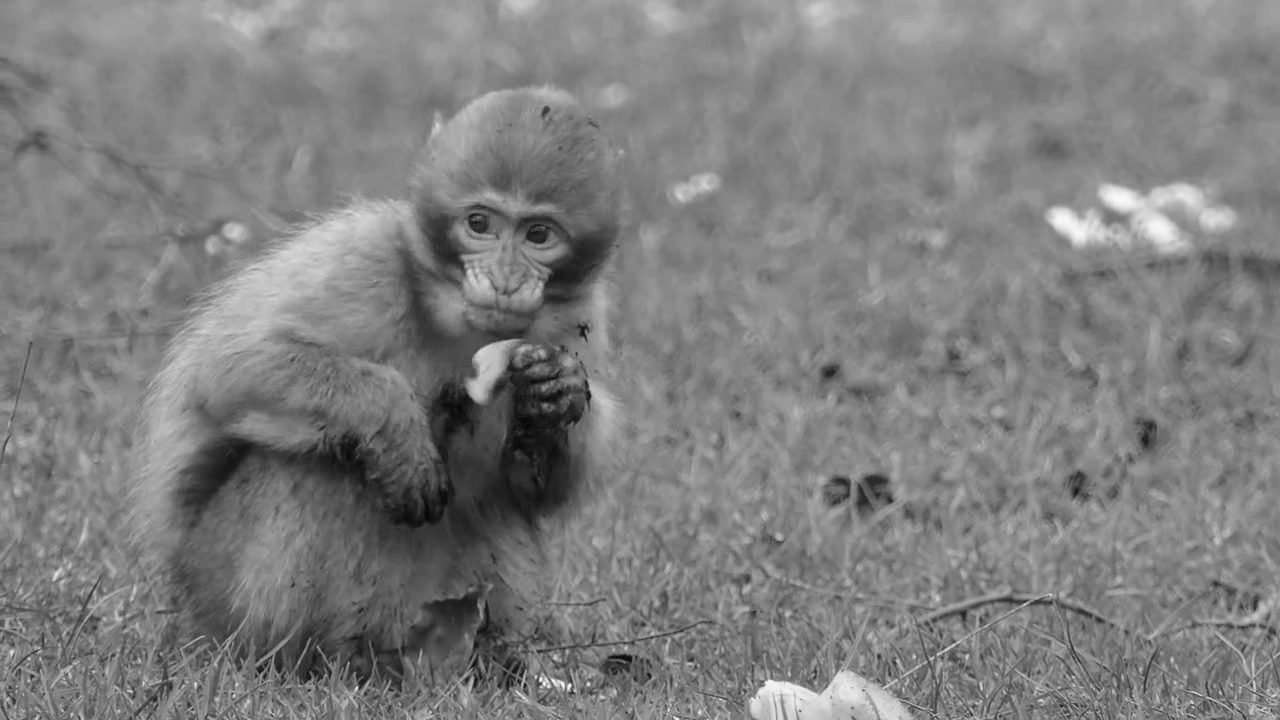

비디오 종료(or 프레임 읽기 실패)
Done. frames=85, elapsed=0.60s


In [ ]:
start_time = time.time() # 프로그램의 시작 시각을 변수에 저장
frame_idx = 0 # 프레임 번호를 세는 카운터 변수

if not cap.isOpened(): # cap.isOpened()는 이 객체가 정상적으로 열렸는지 확인하는 메서드
    print("비디오 파일을 열 수 없습니다. 경로를 확인하세요.")
else:
    try:
        while True:
            # 시간 제한 종료
            if time.time() - start_time > timeout_sec:
                print("시간 제한 종료.")
                break

            # 프레임 수 제한 종료
            if frame_idx >= max_frames:
                print("프레임 수 제한 종료.")
                break

            ret, frame = cap.read() # ret	프레임을 정상적으로 읽었는지 여부
            if not ret:
                print("비디오 종료(or 프레임 읽기 실패)")
                break

            # 그레이스케일 변환 색상 정보를 밝기 값으로 변환해 표현하는 이미지 방식
            gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

            #  N프레임마다 출력 (너무 잦은 출력시 느려질 수 있음)
            if frame_idx % show_every == 0:
                clear_output(wait=True)
                cv2_imshow(gray_frame)

            frame_idx += 1

    except KeyboardInterrupt:
        print("사용자 중단(KeyboardInterrupt)으로 종료합니다.")

    finally:
        cap.release()
        cv2.destroyAllWindows()

elapsed = time.time() - start_time # elapsed 경과한 시간
print(f"Done. frames={frame_idx}, elapsed={elapsed:.2f}s") # {elapsed:.2f}는 소수점 자릿수를 지정

In [ ]:
# !pip list                  # 설치된 패키지 목록

In [ ]:
# !pip show pandas           # 패키지 정보(버전, 위치 등)